In [1]:
#Useful Imports

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio,display,HTML
import seaborn as sns
import scipy.signal as signal
import math
from scipy.io import wavfile
%matplotlib inline
sns.set_style("white")

fs = 44100 
#Similar to last time, the default sampling frequency is chosen to be 44.1 kHz. This frequency in Hz is 
# high enough to cover the full spectrum of human hearing,since the max frequency humans can hear is roughly 20kHz and satisfy the
# Nyquist theorem.



## Synthesizer Implementation(from Assignment 2)

In [ ]:

# Waveform generation functions
#generate sinusoids
def generate_sinusoid(freq, sample_rate = 44100, duration: float=1):
    t = np.arange(0, duration, 1/sample_rate)
    return t, np.sin(2 * np.pi * freq * t)

#To make a square wave, we use the phase. The variable "phase" gives how far we are into the current cycle (since Hz * sec = cycles and %1 leaves us with
# a value betwee 0 and 1 representing how close we are to finishing the current cycle). From here, we can set the value to +-1 depending on the duty cycle the user wants.
def generate_square_wave(freq, sample_rate = 44100, duration: float=1, duty_cycle = 0.5):
    t = np.arange(0, duration, 1/sample_rate)
    
    phase = (t*freq) % 1
    square_wave = np.where(phase< duty_cycle, 1,-1) 
    return t, square_wave

# A ramp is the integral of a square. Thus, we can use the generate_square_wave function to generate a triangle by integrating.
def generate_triangle_wave(freq, sample_rate=44100, duration: float=1):
    t = np.arange(0, duration, 1/sample_rate)
    square_wave =  generate_square_wave(freq, sample_rate, duration)[1]
    triangle_wave = np.cumsum(square_wave) / sample_rate
    triangle_wave = 4* freq * triangle_wave - 1
    return t, triangle_wave

# To generate a sawtooth wave, we use the same phase idea from generating the square wave.
def generate_sawtooth_wave(freq, sample_rate=44100, duration: float=1):
    t = np.arange(0, duration, 1/sample_rate)
    phase = (freq * t) % 1
    sawtooth_wave = phase  # Create a sawtooth wave using the phase information
    return t, 2*sawtooth_wave-1


# ADSR Function(all times will be in ms)
# A = attack(time to go from 0 to 1(or peak amplitude which is 1 in our case))
# D = decay(time to go from peak amplitude to sustain level)
# S = sustain(level at which the signal is maintained)
# R = release(time to go from sustain level to 0)


def adsr_envelope(a,d,s,r,duration,fs=44100, attack_exponential_factor = 0, decay_exponential_factor = 0, release_exponential_factor = 0):
    #Note: duration must match note length to avoid error
    total_samples = int(duration * fs)
    
    attack_samples = int(a * fs)
    decay_samples = int(d * fs)
    release_samples = int(r * fs)

    sustain_samples = total_samples - (attack_samples + decay_samples + release_samples)

    # Since we now know the start/end points of each segment, and the time length of each, we can create the ADSR envelope by
    # interpolating. The method of interpolation is up to the user and is determined by the exponential factors passed into the function.
    # A factor of 0 is obviously a linear interpolation, and is the same as a regular fit. 
    # Exponential factors are allowed to be used for attack and decay segments, but are unlikely to be used for all at the 
    # same time(especially for attack).Nonetheless, they are interesting and may be useful depending on the use case. 
    # A more detailed explanation of the exponential factors is given in the comments below.

    #to avoid division by 0, the linear case is a special case and we do a regular linear interpolation without additional math.
    attack = np.linspace(0, 1, attack_samples)
    if attack_exponential_factor != 0:
        m = (1 - np.exp(-attack_exponential_factor * np.linspace(0, 1, attack_samples))) / (1 - np.exp(-attack_exponential_factor))
        attack = 0 + (1 - 0) * m


    #To implement nonlinear decay, we can add a varying slope that decreases as we get closer to the destination(exponential decay).
    #In other words, we perform the following operation: value = start + (end - start) * m
    #Where we set m to go from 0 to 1 along an exponential over the course of the decay segment. The exponential is determined by 
    #the decay_exponential_factor parameter above.
    #Obviously, if the exponential factor is 0 we reduce to a simple linear case.
    #If the exponential factor is less than 0, we have a concave down curve, and if it is greater than 0 we have a concave up curve.
    #For the sustain decay, we know the start value(1 is given) and the sustain value is passed into the function.

    # In other words, a positive factor means a fast early change while a negative factor means a slow early change.

    decay = np.linspace(1, s, decay_samples)
    if decay_exponential_factor != 0:
        #overwrite m
        m = (1 - np.exp(-decay_exponential_factor * np.linspace(0, 1, decay_samples))) / (1 - np.exp(-decay_exponential_factor))
        decay = 1 + (s - 1) * m
    else:
        decay = np.linspace(1, s, decay_samples)

    sustain = np.full(sustain_samples, s)

    release = np.linspace(s, 0, release_samples)
    if release_exponential_factor != 0:
        #Similarly, we can implement a nonlinear release segment. Same as before, exponential factor of 0 is linear and is the default case
        m = (1 - np.exp(-release_exponential_factor * np.linspace(0, 1, release_samples))) / (1 - np.exp(-release_exponential_factor))
        release = s + (0 - s) * m
    

    adsr_envelope = np.concatenate((attack, decay, sustain, release))
    return adsr_envelope


def lowpass_filter(input_signal, cutoff_f, fs=44100, type='butter', order=2):
    # Calculate the normalized cutoff frequency
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_f / nyquist

    # Design a specified low-pass filter
    if type == 'butter':
        b, a = signal.butter(order, normal_cutoff, btype='low', analog=False)
    elif type == 'cheby1':
        b, a = signal.cheby1(order, 0.5, normal_cutoff, btype='low', analog=False)
    elif type == 'cheby2':
        b, a = signal.cheby2(order, 20, normal_cutoff, btype='low', analog=False)
    elif type == 'elliptical':
        b, a = signal.ellip(order, 0.5, 20, normal_cutoff, btype='low', analog=False)
    else:
        raise ValueError("Unsupported filter type. Choose from 'butter', 'cheby1', 'cheby2', or 'elliptical'.")

    # Apply the filter to the signal
    filtered_signal = signal.lfilter(b, a, input_signal)
    return filtered_signal,b,a


def bandpass_filter(input_signal,passband,fs=44100,type = 'butter', order = 2):
    # Calculate the normalized cutoff frequencies
    nyquist = 0.5 * fs
    low = passband[0] / nyquist
    high = passband[1] / nyquist

    # Design a specified band-pass filter
    if type == 'butter':
        b, a = signal.butter(order, [low, high], btype='band', analog=False)
    elif type == 'cheby1':
        b, a = signal.cheby1(order, 0.5, [low, high], btype='band', analog=False)
    elif type == 'cheby2':
        b, a = signal.cheby2(order, 20, [low, high], btype='band', analog=False)
    elif type == 'elliptical':
        b, a = signal.ellip(order, 0.5, 20, [low, high], btype='band', analog=False)
    else:
        raise ValueError("Unsupported filter type. Choose from 'butter', 'cheby1', 'cheby2', or 'elliptical'.")

    # Apply the filter to the signal
    filtered_signal = signal.lfilter(b, a, input_signal)
    return filtered_signal,b,a


def highpass_filter(input_signal, cutoff_f, fs=44100, type='butter', order=2):
    # Calculate the normalized cutoff frequency
    nyquist = 0.5 * fs
    normal_cutoff = cutoff_f / nyquist

    # Design a specified high-pass filter
    if type == 'butter':
        b, a = signal.butter(order, normal_cutoff, btype='high', analog=False)
    elif type == 'cheby1':
        b, a = signal.cheby1(order, 0.5, normal_cutoff, btype='high', analog=False)
    elif type == 'cheby2':
        b, a = signal.cheby2(order, 20, normal_cutoff, btype='high', analog=False)
    elif type == 'elliptical':
        b, a = signal.ellip(order, 0.5, 20, normal_cutoff, btype='high', analog=False)
    else:
        raise ValueError("Unsupported filter type. Choose from 'butter', 'cheby1', 'cheby2', or 'elliptical'.")

    # Apply the filter to the signal
    filtered_signal = signal.lfilter(b, a, input_signal)
    return filtered_signal,b,a

def bandstop_filter(input_signal, stopband,fs=44100,type = 'butter', order = 2):
    nyquist = 0.5 * fs
    low = stopband[0] / nyquist
    high = stopband[1] / nyquist

    # Design a specified band-pass filter
    if type == 'butter':
        b, a = signal.butter(order, [low, high], btype='bandstop', analog=False)
    elif type == 'cheby1':
        b, a = signal.cheby1(order, 0.5, [low, high], btype='bandstop', analog=False)
    elif type == 'cheby2':
        b, a = signal.cheby2(order, 20, [low, high], btype='bandstop', analog=False)
    elif type == 'elliptical':
        b, a = signal.ellip(order, 0.5, 20, [low, high], btype='bandstop', analog=False)
    else:
        raise ValueError("Unsupported filter type. Choose from 'butter', 'cheby1', 'cheby2', or 'elliptical'.")

    # Apply the filter to the signal
    filtered_signal = signal.lfilter(b, a, input_signal)
    return filtered_signal,b,a


#Implementation of an allpass filter
def all_pass_filter(input_signal, fc, fs=44100, order = 1):
    a = (math.tan(math.pi * fc / fs)-1)/(math.tan(math.pi * fc / fs)+1)
    b = np.array([a, 1])
    a = np.array([1, a])
    filtered_signal = input_signal
    for i in range(order):
        filtered_signal = signal.lfilter(b, a, filtered_signal)
    return filtered_signal,b,a


# A function to handle a single musical note being converted into a waveform. An inputted MIDI note is transformed to a desired waveform at its frequency,
# which is then lowpassed and multiplied with a desired ADSR envelope. The ADSR envelope is rescaled if the attack and decay time (their sum) exceeds the desired note duration.
# This allows the user to have long and short notes that still work with their desired envelope.
# Inputs:
    # - midi = a MIDI musical note
    # - hold_time = length of time the note is held in seconds
    # - wave = desired waveform function that is to be generated for this note
    # - a,d,s,r, = ADSR envelope parameters(see ADSR envelope cells above for more information)
    # - cutoff_mult = a multiplier to scale the cutoff frequency of the lowpass filter
    # - env_kwargs = a dictionary that handles additional parameters. For example, the decay_exponential_factor does not have to be used to create an ADSR envelope
    # since it has a default value, but the user can still specify it if they choose.
# Output: a lowpassed waveform multiplied with the desired ADSR envelope



offsets = {"C": 0, "D": 2, "E": 4, "F":5, "G": 7, "A": 9, "B": 11}
accidentals = {"#": 1, "b": -1, "": 0}
voicings = {"F": [53,57,60], "C": [52,55,60]}

#Convert the name of a note to a MIDI note. Following the formula MIDI = 12*(octave+1)+offset
def name_to_midi(name):
    letter = name[0]
    rest = name[1:]
    if rest and rest[0] in ("#","b"):
        acc,octave = rest[0],int(rest[1:])
    else:
        acc,octave = "",int(rest)
    return 12 * (octave+1) + offsets[letter] + accidentals[acc]

#which pitches that will be converted into frequencies make up a chord
#TODO: Make a function for generating voicings. This will allow to play higher/lower chords.
voicings_names = {"F": ["F3","A3","C4"],
                  "C": ["E3","G3","C4"],
                  "G": ["D3","G3","B3"],
                  "Am":["C3","E3","A3"],
                  "C#m": ["E3","G#3","C#4"]}
voicings = {k: [name_to_midi(n) for n in v] for k, v in voicings_names.items()}



#parse_bars converts bars into a suitable format for render_track
def parse_bars(bars, beats_per_bar = 4):
    melody, chords = [],[]
    for i, [chord, notes] in enumerate(bars):
        bar_start = i*beats_per_bar
        for j in voicings[chord]:
            chords.append((j,bar_start,beats_per_bar))

        #melody
        t = bar_start
        for j in notes:
            name,_,length = j.partition(":")
            length = float(length) if length else 1.0
            melody.append((name_to_midi(name),t,length))
            t+=length
    return melody, chords

def midi_to_freq(m):
    return 440 * 2 ** ((m - 69) / 12)  

def render_note(midi, hold_time, wave, a,d,s,r,cutoff_mult,**env_kwargs):
    freq = midi_to_freq(midi)
    
    if a + d > hold_time:
        scale = hold_time/(a+d)
        a,d = a*scale,d*scale

    total_time = hold_time + r
    adsr = adsr_envelope(a,d,s,r,fs=fs,duration = total_time,**env_kwargs)

    note_waveform = wave(freq,fs,len(adsr)/fs)[1][:len(adsr)]

    cutoff = freq*cutoff_mult
    note_waveform = lowpass_filter(note_waveform,cutoff,fs=fs)[0]

    return note_waveform * adsr[:len(note_waveform)]

#A function for processing a time audio track. It calls render_note() for each note,
# using the synthesizer built above to produce the final musical waveform
def render_track(notes,bpm=120, **voice_params):
    seconds_per_beat = 60/bpm
    last_end = max((st+ln)*seconds_per_beat for _, st,ln in notes)+2
    out = np.zeros(int(last_end*fs))
    for midi,start_beat,len_beats, in notes:
        note = render_note(midi,len_beats*seconds_per_beat,**voice_params)
        i = int(start_beat*fs*seconds_per_beat)
        out[i:i+len(note)]+=note
    return out



## Tester figure demonstrating synthesizer functionality. A sample waveform is generated, lowpassed, and fitted with an ADSR envelope. Finally, it passes through a highpass filter. The audio samples of the original waveform, the lowpass+ADSR envelope output, and the final allpassed output are also available for playback.

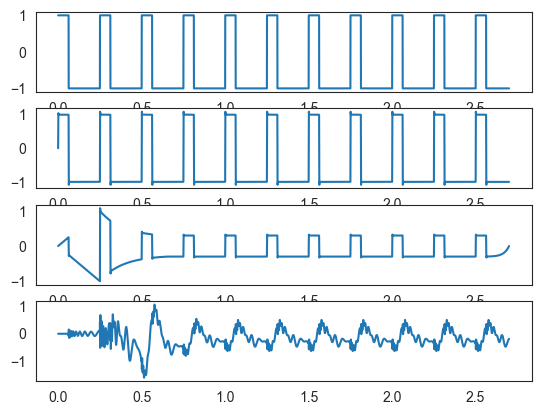

In [71]:
sample_duration = 2.7
t,tester_square = generate_square_wave(4,sample_rate=44100,duration = sample_duration, duty_cycle = 0.25)
tester_filter = lowpass_filter(tester_square,cutoff_f=500)[0]
tester_envelope = adsr_envelope(a=0.25,d=0.40,s=0.3,r=0.15,duration = sample_duration,decay_exponential_factor=3,release_exponential_factor=-5)
tester_adsr=tester_filter*tester_envelope
tester_allpass = all_pass_filter(tester_adsr,20,order=20)[0]

plt.figure()
plt.subplot(4,1,1)

plt.plot(t,tester_square)

plt.subplot(4,1,2)

plt.plot(t,tester_filter)

plt.subplot(4,1,3)

plt.plot(t,tester_adsr)

plt.subplot(4,1,4)
plt.plot(t,tester_allpass)
plt.show()

display(Audio(tester_allpass,rate=fs))

 

In [74]:
#Making a clean song with spaceship background sounds
#All music related information is taken from piano.org
#bars is used to describe the song in an array type format
bars = [
 ("F", ["A4","G4","F4","G4"]),
 ("F", ["A4","A4","A4:2"]),
 ("C", ["G4","G4","G4:2"]),
 ("F", ["A4","C5","C5:2"]),
 ("F", ["A4","G4","F4","G4"]),
 ("F", ["A4","A4","A4","A4"]),
 ("C", ["G4","G4","A4","G4"]),
 ("F", ["F4:4"]),
]
melody, chords = parse_bars(bars)
lead = render_track(melody, wave = generate_sawtooth_wave,a=5,d=150,s=0.3,r=150,cutoff_mult = 6,decay_exponential_factor = 3)
pad =  render_track(chords,wave = generate_triangle_wave, a=120,d=100,s=0.8,r=400,cutoff_mult = 3)
n = max(len(lead),len(pad))

lead = np.pad(lead,(0,n-len(lead)))
pad = np.pad(pad,(0,n-len(pad)))
mixed = 0.7*lead + 0.3*pad
allpassed = all_pass_filter(mixed,800,fs,order=6)[0]
allpass_mixed = 0.5*mixed+0.5*allpassed
allpass_mixed = allpass_mixed/(np.max(np.abs(allpass_mixed)))


#import impulse response taken from the engine room of a submarine

fs_ir,ir = wavfile.read("USS Dolphin Submarine Control Room.wav")
ir = ir.astype(float)
print(ir.shape,fs_ir)
ir = ir/np.sum(np.abs(ir))
if ir.ndim == 2:
    ir = ir.mean(axis=1)
    

mixed = signal.fftconvolve(allpass_mixed,ir)
mixed_length = len(mixed) # is equal to len(ir)+len(allpass_mixed)-1  

display(Audio(mixed,rate=fs))
    



NameError: name 'beat' is not defined